# Vegetables Classification using Deep Convolutional Neural Network (DCNN)
Sesuai dengan instruksi soal kuis DL 1 (VeggieLKa), notebook ini berisi alur lengkap dari load data, split, preprocessing, pemodelan DCNN, training, evaluasi, hingga visualisasi metrik.

### 1. Import Libraries
Mengimpor pustaka TensorFlow, NumPy, Matplotlib, serta fungsi utilitas untuk split data dan image processing.

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from tensorflow.keras.utils import load_img, img_to_array, to_categorical

### 2. Load Dataset & Shuffle
- `PATH`: Path folder dataset (`./Dataset`).
- `CLASS_NAMES`: 4 kelas sayuran (`Broccoli`, `Carrot`, `Cucumber`, `Tomato`).
- Gambar dimuat dalam format `grayscale` dengan ukuran `(64, 64)` dan seluruh gambar (500 gambar per kelas) dimuat.
- Dilakukan `shuffle` acak pada dataset sebelum proses split sesuai instruksi *'Randomly shuffle the dataset'*.

In [8]:
PATH = './Dataset'
CLASS_NAMES = ['Broccoli', 'Carrot', 'Cucumber', 'Tomato']

images, labels = [], []
for idx, name in enumerate(CLASS_NAMES):
    folder = os.path.join(PATH, name)
    for file in os.listdir(folder):
        # Load gambar dalam mode grayscale (1 channel) dengan ukuran 64x64
        img = load_img(os.path.join(folder, file), target_size=(64, 64), color_mode='grayscale')
        images.append(img_to_array(img))
        labels.append(idx)

# Randomly shuffle dataset agar urutan kelas teracak merata
images, labels = shuffle(np.array(images), np.array(labels), random_state=42)

### 3. Split Dataset (80 / 10 / 10)
Membagi dataset menjadi 3 bagian sesuai instruksi:
- Training set: 80% (1600 gambar)
- Validation set: 10% (200 gambar)
- Testing set: 10% (200 gambar)

In [9]:
# Tahap 1: Pisahkan 80% data latih dan 20% data sementara
x_train, x_temp, y_train, y_temp = train_test_split(images, labels, test_size=0.2, random_state=42)

# Tahap 2: Bagi 20% data sementara menjadi 10% validasi dan 10% uji (50:50 dari x_temp)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42)

### 4. Data Preprocessing
- Mengubah tipe data piksel ke `float32`.
- Normalisasi nilai piksel dengan membagi 255.0 (`[0, 255] -> [0.0, 1.0]`).
- Mengubah label target menjadi format categorical (*one-hot encoding*) menggunakan `to_categorical`.

In [10]:
# Konversi data ke tipe float32 dan normalisasi nilai piksel ke rentang [0, 1]
x_train = x_train.astype('float32') / 255.0
x_val = x_val.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# One-hot encoding untuk target variable sesuai jumlah kelas (4)
y_train = to_categorical(y_train, num_classes=len(CLASS_NAMES))
y_val = to_categorical(y_val, num_classes=len(CLASS_NAMES))
y_test = to_categorical(y_test, num_classes=len(CLASS_NAMES))

### 5. DCNN Architecture (Visualization, Initialization, Configuration)
Arsitektur sesuai dengan visualisasi blok pada **Figure 1**:
- **Input Layer**: `(64, 64, 1)`
- **Hidden Layers**:
  1. `Conv2D(16, (3,3), padding='same', activation='relu')`
  2. `MaxPooling2D((2,2))`
  3. `Conv2D(32, (3,3), padding='same', activation='relu')`
  4. `Conv2D(32, (3,3), padding='same', activation='relu')`
  5. `MaxPooling2D((2,2))` (standar pooling 2x2, bukan AdaptiveMaxPooling)
  6. `Flatten()`
- **Output Layer**:
  1. `Dense(32, activation='relu')`
  2. `Dense(4, activation='softmax')`

In [11]:
model = tf.keras.Sequential([
    # Input Layer (resolusi 64x64, 1 channel grayscale)
    tf.keras.layers.Input(shape=(64, 64, 1)),
    
    # Hidden Layers sesuai diagram Figure 1
    tf.keras.layers.Conv2D(16, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    
    # Output Layer (Dense ReLU dan Dense Softmax)
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(len(CLASS_NAMES), activation='softmax')
])

# Kompilasi model dengan Adam optimizer, loss Categorical Crossentropy, dan metrik accuracy
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       262,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276,356 (1.05 MB)

 Trainable params: 276,356 (1.05 MB)

 Non-trainable params: 0 (0.00 B)

### 6. Model Training
Melatih model selama 10 epochs dengan `batch_size=32`. Jumlah langkah per epoch adalah 1600 / 32 = 50 langkah (sesuai Figure 2).

In [12]:
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.4506 - loss: 1.1784 - val_accuracy: 0.6400 - val_loss: 0.8902
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7469 - loss: 0.7045 - val_accuracy: 0.7350 - val_loss: 0.6306
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8019 - loss: 0.5019 - val_accuracy: 0.7650 - val_loss: 0.6241
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8506 - loss: 0.3944 - val_accuracy: 0.8700 - val_loss: 0.3804
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8406 - loss: 0.3785 - val_accuracy: 0.8500 - val_loss: 0.4170
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8913 - loss: 0.2903 - val_accuracy: 0.8600 - val_loss: 0.3827
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9150 - loss: 0.2398 - val_accuracy: 0.8900 - val_loss: 0.3275
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9344 - loss: 0.1957 - val_accuracy: 0.8950 - v

### 7. Predicting Data & Model Evaluation
- **Predict Data**: Melakukan prediksi pada `x_test`.
- **Model Evaluation**: Mengevaluasi performa model pada data uji dan menampilkan nilai `Test Accuracy` serta `Test Loss` persis seperti pada **Figure 3 & Figure 4**.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8750 - loss: 0.3638 
Test Accuracy :  0.875
Test Loss     :  0.3637908697128296


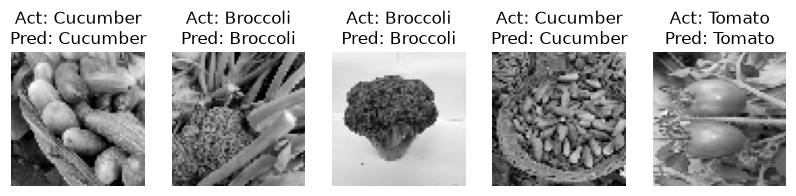

In [13]:
# Memprediksi hasil data uji
y_pred = model.predict(x_test)

# Evaluasi pada data uji dan cetak loss serta accuracy
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f'Test Accuracy :  {test_accuracy}')
print(f'Test Loss     :  {test_loss}')

# Visualisasi prediksi gambar (5 sampel)
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.title(f"Act: {CLASS_NAMES[np.argmax(y_test[i])]}\nPred: {CLASS_NAMES[np.argmax(y_pred[i])]}")
    plt.axis('off')
plt.show()


### 8. Plot of Evaluation Metrics
Menampilkan grafik metrik evaluasi persis sesuai format **Figure 5**:
- Subplot kiri: `Accuracy [%]` (Training vs Validation Accuracy, ylim [0.0, 1.0], legend di lower right).
- Subplot kanan: `Loss [%]` (Training vs Validation Loss, ylim [0.0, 3.0], legend di upper right).

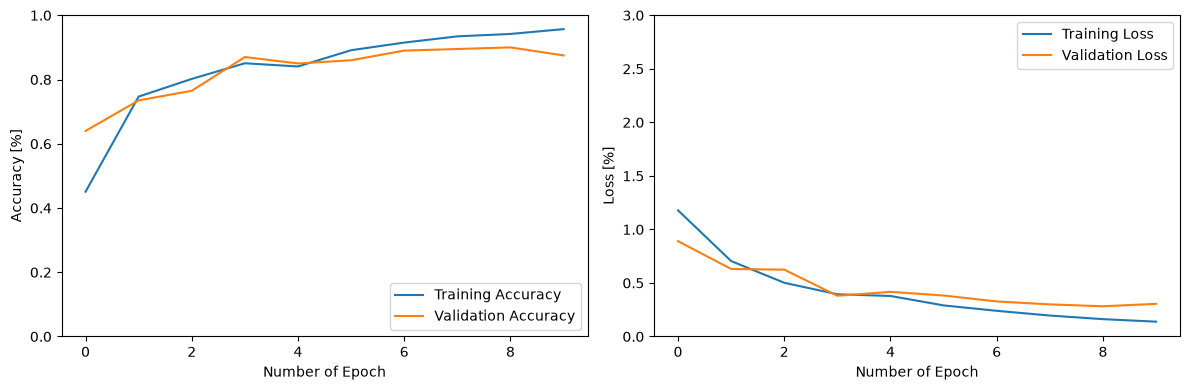

In [14]:
plt.figure(figsize=(12, 4))

# Subplot 1: Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Number of Epoch')
plt.ylabel('Accuracy [%]')
plt.ylim([0.0, 1.0])
plt.legend(loc='lower right')

# Subplot 2: Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Number of Epoch')
plt.ylabel('Loss [%]')
plt.ylim([0.0, 3.0])
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()